In [1]:
import cv2
import numpy as np
import torch
import algorithms.kernelDL_multistep as kdl
import algorithms.dmd as edmd
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import utils.kernels as kernels
import utils.helpers as helpers
import utils.plotting_params

# koopmanAE
from koopmanAE.model import koopmanAE
from koopmanAE.train import train
from koopmanAE.tools import *

%load_ext autoreload
%autoreload 2

Connected to a GPU


In [240]:
import cv2

def get_video_info_cv2(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise IOError(f"Cannot open video: {path}")

    info = {
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "n_frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "fourcc": int(cap.get(cv2.CAP_PROP_FOURCC)),
    }
    info["duration_sec"] = info["n_frames"] / info["fps"] if info["fps"] else None
    cap.release()
    return info



In [2]:
def data_loader(file_path):
    cap = cv2.VideoCapture(file_path)
    if not cap.isOpened():
        raise IOError(f"Cannot open video file: {file_path}")

    gray_frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        # Convert BGR → Grayscale
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        # Normalize to range [0, 1] as float32
        gray_norm = gray.astype(np.float32) / 255.0
        gray_frames.append(gray_norm)

    cap.release()
    return np.array(gray_frames, dtype=np.float64)

In [242]:
filepath = "../../data/Pendulum.mpg"
pendulum_data =  data_loader(file_path=filepath)

In [244]:
info = get_video_info_cv2(filepath)
print(info)

{'width': 720, 'height': 576, 'fps': 25.0, 'n_frames': 523, 'fourcc': 845639789, 'duration_sec': 20.92}


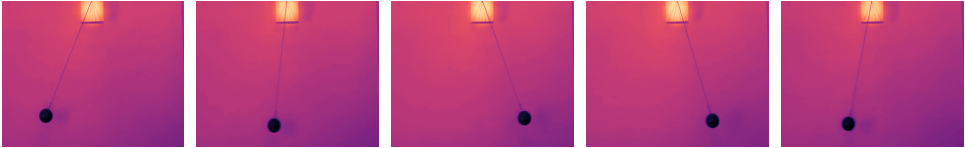

In [4]:
nrow, ncol = 1, 5
lag = 10
fig, axes = plt.subplots(nrow, ncol, figsize= (6.5*nrow, 4.5*ncol), sharex=True, sharey=True, constrained_layout=True)
axes = axes.flatten()
for i, ax in enumerate(axes):
    ax.imshow(pendulum_data[i * lag], cmap='magma')
    ax.grid(False)
    ax.axis('off')
plt.show()

In [5]:
background = np.median(pendulum_data, axis=0)
T, W, H = pendulum_data.shape

Xall = (pendulum_data - background).reshape(T,-1).T
p_train = .8
Xtrain, Xtest = Xall[:, :int(p_train * T)], Xall[:, int(p_train * T):]

In [6]:
# compute the SVD of the training data
U, S, Vt = np.linalg.svd(Xtrain, full_matrices=False)

In [12]:
# retain 90% of the total energy
e = 0.9
cum_energy = np.cumsum(S**2) / np.sum(S**2)
r = np.searchsorted(cum_energy, e) + 1
print(f"Retained {r} components out of {len(S)}")

# Dimensionality reduction
Xtrain_r = S[:r, np.newaxis] * Vt[:r, :]
Xtest_r = U[:,:r].T @ Xtest 

Retained 14 components out of 418


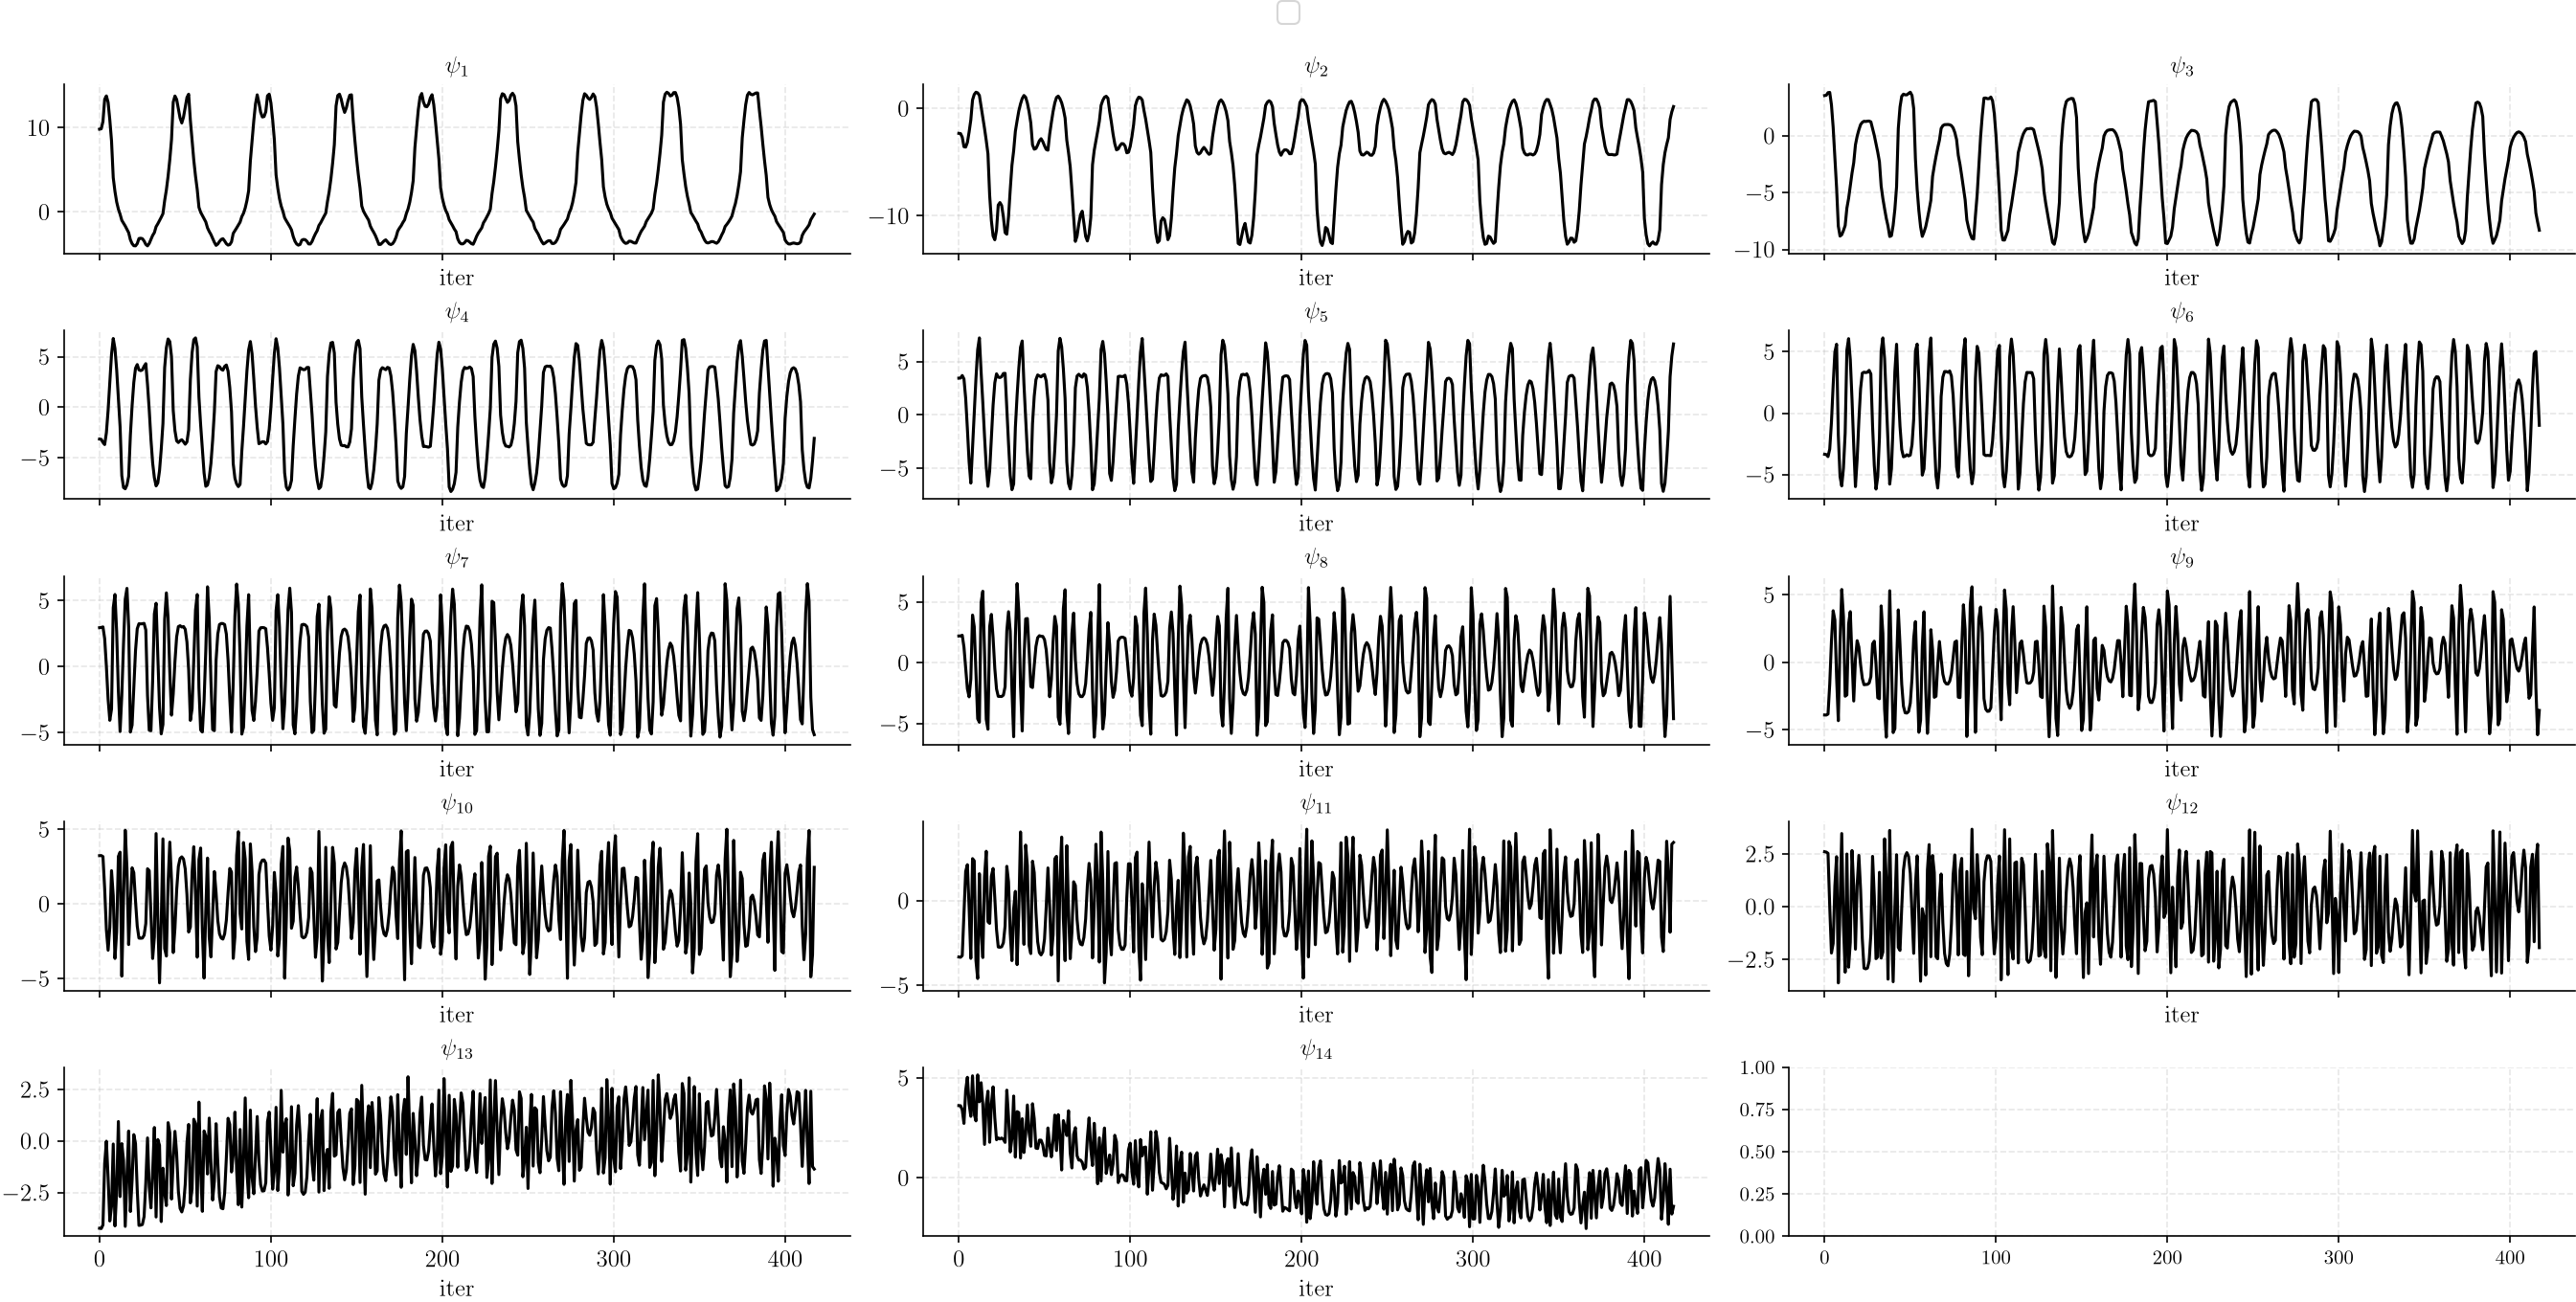

In [14]:
ncols = 3
nrows = int(np.ceil(r/ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*6, nrows*1.75), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i in range(Xtrain_r.shape[0]):
    ax[i].plot(Xtrain_r[i, :], color='black')
    ax[i].set_xlabel('iter', fontsize=12)
    ax[i].set_title(rf'$\psi_{{{i+1}}}$', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, fontsize=14, bbox_to_anchor=(0.5,1.05))
plt.show()

In [15]:
# scaling 
c = Xtrain_r.min(axis=1, keepdims=True)
d = np.ptp(Xtrain_r, axis=1, keepdims=True)
Xtrain_scaled = (Xtrain_r - c) / d
Xtest_scaled = (Xtest_r - c) / d

### cKAE

In [211]:
steps, steps_back, backward, epochs = 12, 12, 1, 600   # koopmanAE
dim = Xtrain_scaled.shape[0]
embed_dim = 8
seed = 0
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.manual_seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
set_seed(seed)
device = get_device()

batchsize=64; init_scale=0.99; alpha_=4
lr=1e-2; wd=0; lamb=1; lr_decay=0.2; lr_update=[50*(i+1) for i in range(epochs//50)];
nu=1e-1; eta=1e-2; gradclip=0.05; 


#****************************************************************
#     prepare dataset for koopmanAE
#****************************************************************
X_train_kae = add_channels(Xtrain_scaled.T)

# create dataloader
X_train_kae = torch.from_numpy(X_train_kae).float().contiguous()
trainDat = []
start = 0
for i in np.arange(steps,-1, -1):
    if i == 0:
        trainDat.append(X_train_kae[start:].float())
    else:
        trainDat.append(X_train_kae[start:-i].float())
    start += 1

train_data = torch.utils.data.TensorDataset(*trainDat)
del(trainDat)

train_loader = torch.utils.data.DataLoader(dataset = train_data, batch_size = batchsize, shuffle = True)

#*************************************************************
#             Model
#*************************************************************
model = koopmanAE(dim, 1, embed_dim, steps, steps_back, alpha_, init_scale)
model = model.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model.parameters())/1000.0))
print('************')
print(model)

#==============================================================================
# Training
#==============================================================================
model, optimizer, epoch_hist = train(model, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

Connected to a GPU
**** Setup ****
Total params: 0.01M
Total params: 11.41k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=14, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=64, bias=True)
    (fc3): Linear(in_features=64, out_features=8, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=8, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=64, bias=True)
    (fc3): Linear(in_features=64, out_features=14, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.8878632187843323
loss backward:  1.3069121837615967
loss consistent:  13.041885375976562
loss forward:  1.2572615146636963
loss sum:  2.4062347412109375
********** Epo

### KAE

In [212]:
seed = 0
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.cuda.manual_seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
set_seed(seed)

#*************************************************************
#             Model
#*************************************************************
nu=0.0; eta=0.0; backward=0; steps_back=0,
model_kae = koopmanAE(dim, 1, embed_dim, steps, steps_back, alpha_, init_scale)
model_kae = model_kae.to(device)

print('**** Setup ****')
print('Total params: %.2fM' % (sum(p.numel() for p in model_kae.parameters())/1000000.0))
print('Total params: %.2fk' % (sum(p.numel() for p in model_kae.parameters())/1000.0))
print('************')
print(model_kae)

#==============================================================================
# Training
#==============================================================================
model_kae, optimizer, epoch_hist = train(model_kae, train_loader, lr=lr, weight_decay=wd, lamb=lamb, num_epochs = epochs,
                    learning_rate_change=lr_decay, epoch_update=lr_update,nu = nu, eta = eta, backward=backward,
                    steps=steps, steps_back=steps_back, gradclip=gradclip)

**** Setup ****
Total params: 0.01M
Total params: 11.41k
************
koopmanAE(
  (encoder): encoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=14, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=64, bias=True)
    (fc3): Linear(in_features=64, out_features=8, bias=True)
  )
  (dynamics): dynamics(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (backdynamics): dynamics_back(
    (dynamics): Linear(in_features=8, out_features=8, bias=False)
  )
  (decoder): decoderNet(
    (tanh): Tanh()
    (fc1): Linear(in_features=8, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=64, bias=True)
    (fc3): Linear(in_features=64, out_features=14, bias=True)
  )
)
Connected to a GPU
********** Epoche 1 **********
loss identity:  0.8937333226203918
loss forward:  1.2949413061141968
loss sum:  2.1886746883392334
********** Epoche 21 **********
loss identity:  0.0574820302426815
loss forward:  0.8709074258804321
loss

### EDMD-kDL

In [246]:
seed = 42
X, Y = Xtrain_scaled[:, :-1], Xtrain_scaled[:, 1:] 

# generate collocation points
dim = X.shape[0]
mc, seed = 7, 42
l_bounds = [X.min() -1.]*dim 
u_bounds = [X.max() + 1.]*dim 
Z = helpers.generate_collocation_points(dim, l_bounds, u_bounds, m=mc, seed=seed).T

In [248]:
fixed_feature_fn = lambda x: x
sigma, p, gamma = 5, dim*3, 1e-8
kernel = kernels.gaussianKernel(sigma=sigma)
edmd_kdl = kdl.EDMDkDL(X=X, Y=Y, Z=Z, kernel=kernel, p=p, gamma=gamma, decoder=True, fixed_feature_fn=fixed_feature_fn)    

In [249]:
# edmd_kdl.optimize(n_iters=3000, steps=12, beta1=1, beta2=1, beta3=1e-10, verbose_after=20,
#                    history_size=10, max_iter=10, line_search_fn='strong_wolfe')
edmd_kdl.optimize(n_iters=1000, steps=12, beta1=1, beta2=1, beta3=1e-8, verbose_after=20, history_size=60)

step   0 | loss 1.6e+19
step  20 | loss 1.6e+06
step  40 | loss 1.7e+05
step  60 | loss 4.8e+04
step  80 | loss 1.8e+04
step 100 | loss 5.8e+03
step 120 | loss 1.5e+03
step 140 | loss 1.4e+02
step 160 | loss 1.2e+01
step 180 | loss 1.4e-01
step 200 | loss 1.6e-02
step 220 | loss 4.6e-03
step 240 | loss 2.8e-03
step 260 | loss 2.0e-03
step 280 | loss 1.5e-03
step 300 | loss 1.3e-03
step 320 | loss 1.1e-03
step 340 | loss 1.0e-03
step 360 | loss 8.9e-04
step 380 | loss 7.8e-04
step 400 | loss 7.1e-04
step 420 | loss 6.3e-04
step 440 | loss 5.8e-04
step 460 | loss 5.3e-04
step 480 | loss 4.8e-04
step 500 | loss 4.3e-04
step 520 | loss 3.9e-04
step 540 | loss 3.5e-04
step 560 | loss 3.2e-04
step 580 | loss 2.9e-04
step 600 | loss 2.7e-04
step 620 | loss 2.4e-04
step 640 | loss 2.2e-04
step 660 | loss 2.0e-04
step 680 | loss 1.8e-04
step 700 | loss 1.7e-04
step 720 | loss 1.5e-04
step 740 | loss 1.4e-04
step 760 | loss 1.3e-04
step 780 | loss 1.2e-04
step 800 | loss 1.1e-04
step 820 | loss 

**eigenvalue plot**

In [250]:
# cKAE
K_ckae = model.dynamics.dynamics.weight.data.detach().cpu().numpy()
K_kae = model_kae.dynamics.dynamics.weight.data.detach().cpu().numpy()
eigvals_ckae = np.linalg.eigvals(K_ckae)
eigvals_kae = np.linalg.eigvals(K_kae)
eigvals_edmdkdl = edmd_kdl.eigvals

EigVals = [eigvals_kae, eigvals_ckae, eigvals_edmdkdl]
labels = ['KAE', 'cKAE', 'EDMD-kDL']
colors_list = ['magenta', 'orange', 'darkred', 'darkblue']

fig, axes = plt.subplots(1, len(EigVals), figsize=(4.25, 1.6), constrained_layout=True)

theta = np.linspace(0, 2*np.pi, 200)
unit_circle = np.column_stack([np.cos(theta), np.sin(theta)])

# consistent limits across all panels, based on global max |eigval|
max_extent = max(np.max(np.abs(ev)) for ev in EigVals)
lim = max(1.1, max_extent * 1.1)  # pad beyond unit circle / data, whichever is larger

for i, (ax, eigvals) in enumerate(zip(axes, EigVals)):
    ax.plot(unit_circle[:, 0], unit_circle[:, 1], color='gray', ls='--', lw=0.6, zorder=1)
    ax.vlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.hlines(0, -1, 1, color='gray', ls='--', lw=0.2)
    ax.scatter(eigvals.real, eigvals.imag, color=colors_list[i], s=5, linewidths=0,
               zorder=2, clip_on=False)

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_title(labels[i], fontsize=12, pad=3)
    ax.set_xlabel(r'Re($\lambda$)', fontsize=12)
    ax.tick_params(labelsize=12, length=2)

    if i == 0:
        ax.set_ylabel(r'Im($\lambda$)', fontsize=12)
    else:
        ax.set_yticklabels([])  

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.grid(False)

fig.savefig('figures/video_pendulum_eigvals.pdf', bbox_inches='tight')
plt.close(fig)

In [251]:
M = Xtest_scaled.shape[1]
x0 = Xtest_scaled[:,0]
x0_kae = torch.from_numpy(add_channels(Xtest_scaled.T)[0]).contiguous().float()

# ckae
with torch.no_grad():
    z0 = model.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_ckae_scaled = model.decoder(Zpred).squeeze().T.cpu().numpy()

# kae
with torch.no_grad():
    z0 = model_kae.encoder(x0_kae.to(device))
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(model_kae.dynamics(Zpred[i]))
    Zpred = torch.cat(Zpred)
    X_kae_scaled = model_kae.decoder(Zpred).squeeze().T.cpu().numpy()

# edmd-kdl
with torch.no_grad():
    z0 = edmd_kdl.psi_fn(x0).squeeze()
    Zpred = [z0]
    for i in range(M-1):
        Zpred.append(edmd_kdl.learned_linear_model(Zpred[i]))
    Zpred = np.array(Zpred).T
    X_edmdkdl_scaled = edmd_kdl.decoder_fn(Zpred) if edmd_kdl.decoder else Zpred[:dim, :]
X_edmdkdl_scaled = X_edmdkdl_scaled.numpy() if isinstance(X_edmdkdl_scaled, torch.Tensor) else X_edmdkdl_scaled

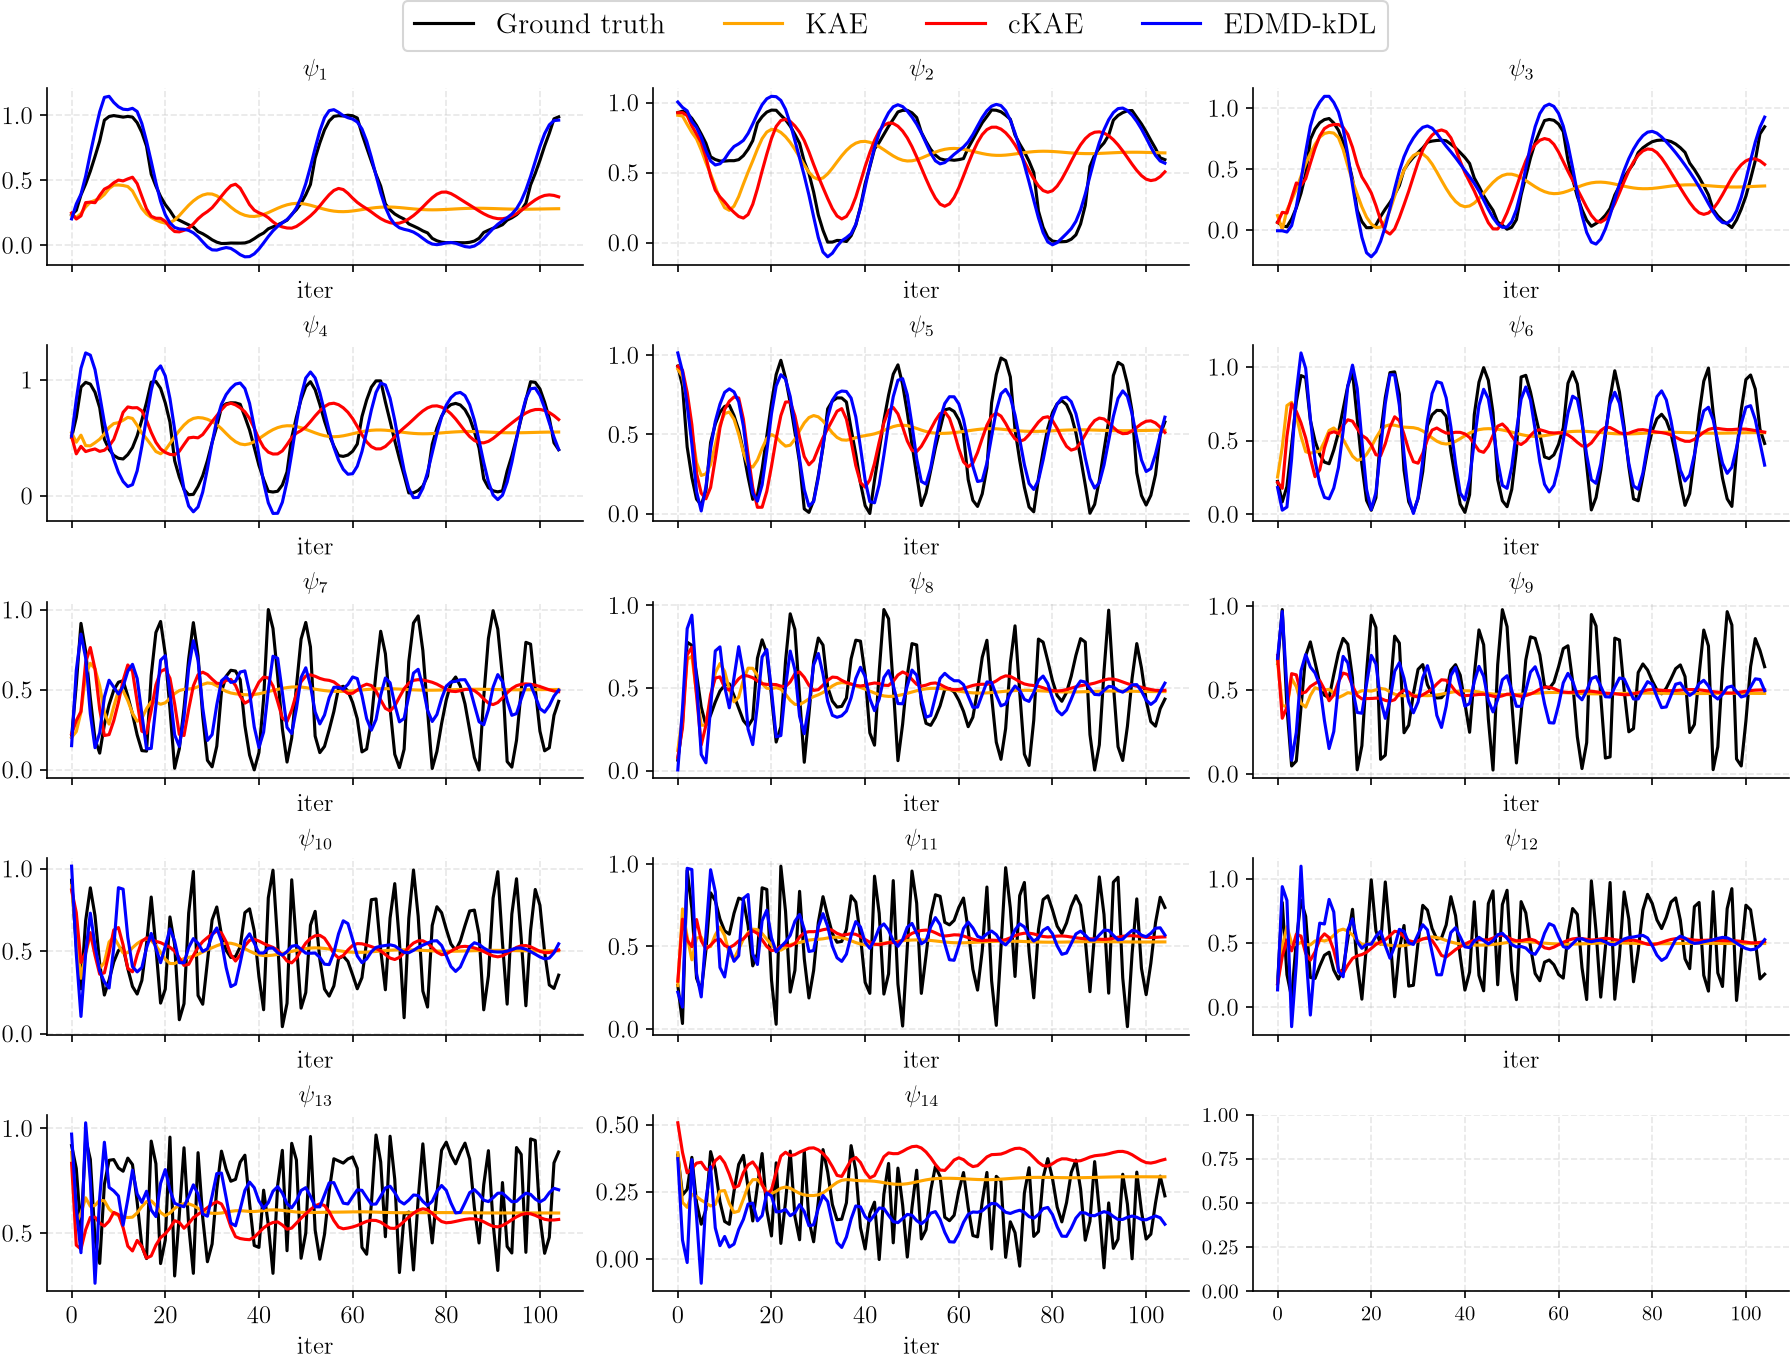

In [252]:
ncols = 3
nrows = int(np.ceil(dim/ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*1.75), sharex=True, constrained_layout=True)
ax = ax.flatten()
for i in range(dim):
    ax[i].plot(Xtest_scaled[i, :], color='black',  label="Ground truth")
    ax[i].plot(X_kae_scaled[i, :], color='orange', label="KAE")
    ax[i].plot(X_ckae_scaled[i, :], color='red',  label="cKAE")
    ax[i].plot(X_edmdkdl_scaled[i, :], color='blue',  label="EDMD-kDL")
    ax[i].set_xlabel('iter', fontsize=12)
    ax[i].set_title(rf'$\psi_{{{i+1}}}$', fontsize=12)
    ax[i].tick_params(axis='both', labelsize=12)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, fontsize=14, bbox_to_anchor=(0.5,1.05))
plt.show()

**prediction error**

In [319]:
X_edmdkdl = U[:,:r] @ (X_edmdkdl_scaled * d + c)
X_ckae = U[:,:r] @ (X_ckae_scaled * d + c)
X_kae = U[:,:r] @ (X_kae_scaled * d + c)
X_test_recon = U[:,:r] @ Xtest_r

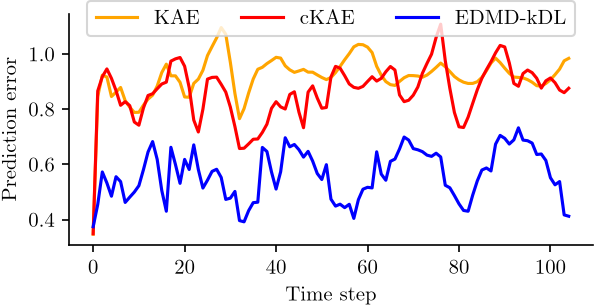

In [254]:
error = np.linalg.norm(Xtest - X_edmdkdl, axis=0) / np.linalg.norm(Xtest, axis=0)

plt.figure(figsize=(4.5, 2))
plt.plot(np.linalg.norm(Xtest - X_kae, axis=0) / np.linalg.norm(Xtest, axis=0), color='orange', label='KAE')
plt.plot(np.linalg.norm(Xtest - X_ckae, axis=0) / np.linalg.norm(Xtest, axis=0), color='red', label='cKAE')
plt.plot(np.linalg.norm(Xtest - X_edmdkdl, axis=0) / np.linalg.norm(Xtest, axis=0), color='blue', label='EDMD-kDL')

plt.xlabel('Time step')
plt.ylabel('Prediction error')
plt.grid(False)
plt.legend(bbox_to_anchor=(0.5, 1.1), loc='upper center', ncol=3, fontsize=10)
plt.show()

**snapshots**

In [320]:
T, W, H = pendulum_data.shape
X_test_m = Xtest.reshape(W,H,-1)
X_test_recon_m = X_test_recon.reshape(W,H,-1)
X_edmdkdl_m = X_edmdkdl.reshape(W,H,-1)
X_kae_m = X_kae.reshape(W,H,-1)
X_ckae_m = X_ckae.reshape(W,H,-1)

In [351]:
times = [0, 10, 20, 40, 60, 80, 100, 104]
datasets = [X_test_m, X_test_recon_m, X_edmdkdl_m, X_kae_m, X_ckae_m]
row_labels = ['Original data', 'Ground truth', 'EDMD-kDL', 'KAE', 'cKAE']
col_labels = ['(a) ', '(b) ', '(c) ', '(d) ', '(e) ', '(f) ', '(g) ', '(h) ']

fig, axes = plt.subplots(len(datasets), len(times), figsize=(1.1*len(times), 0.8*len(datasets)),
                          sharex=True, sharey=True, constrained_layout=True)

# Shared normalization across all panels (both rows)
norm = colors.Normalize(vmin=np.min(X_test_m), vmax=np.max(X_test_m), clip=True)

for row, data in enumerate(datasets):
    for col, t in enumerate(times):
        ax = axes[row, col]
        im = ax.imshow(data[..., t], aspect='auto', interpolation='none', cmap='RdBu_r', norm=norm)
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(col_labels[col] + rf'$t = {t}$', fontsize=10)

    # Row labels (only on left-most column)
    axes[row, 0].text(-0.08, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                       rotation=90, va='center', ha='center', fontsize=9)


fig.savefig('figures/video_pendulum_snapshots.pdf', bbox_inches='tight', format='pdf')
plt.close(fig)